# April vs. January-March: does the Z500/T700 match rate actually improve later in the season?

`CA_snowmelt_events_detrend_5day.ipynb` (Section 5) reports an overall 61%/59%
(T700/Z500) match rate between its 41 Jan-Apr rapid-decline events and the Method A
heat-wave record, but never breaks that number down by month. A fresh-eyes review of
the whole notebook suite proposed (among other things) that the atmospheric fields
"indicate reasonably well the major melt events, and perhaps they do so better later
in the season" -- eyeballing the raw month-by-month split (Feb 67%/83%, Mar 82%/91%,
Apr 50%/38%) suggested the opposite: match rate peaks in March, then drops sharply in
April, which is also the most common onset month (24 of 41 events, 59% of the
sample).

This notebook puts a formal test behind that eyeball read, and asks a second
question it raises: are the unmatched April events smaller, more routine declines
(consistent with ordinary climatological melt-out that doesn't need a detected
ridge), or statistically indistinguishable in size from the matched ones (which would
argue against "ordinary and small" as the explanation)?

Self-contained: reads only the event-table CSVs already exported by
`CA_snowmelt_events_detrend_5day.ipynb` (snow events, with `duration_days`,
`peak_frac`, `mean_frac` as magnitude proxies) and
`CA_z500_t700_blocking_events_detrend_5day.ipynb` (Method A heat-wave events).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, mannwhitneyu
import statsmodels.api as sm

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')


## 1. Load event tables and reproduce the Method A match rate

Sanity check against `CA_snowmelt_events_detrend_5day.ipynb`'s own printed numbers
before splitting by month -- should read 61%/59% (T700/Z500, n=41).

In [2]:
melt = pd.read_csv(DATA_DIR / 'ca_snotel_snowmelt_events_wy1990-2025.csv',
                   parse_dates=['start_date', 'end_date'])
melt['start_date'] = melt.start_date.dt.date
melt['end_date'] = melt.end_date.dt.date
# Z500/T700 heat-wave record only covers Jan-Apr -- restrict exactly as
# CA_snowmelt_events_detrend_5day.ipynb Section 5 does
melt_janapr = melt[melt.start_date.apply(lambda d: d.month in (1, 2, 3, 4))].reset_index(drop=True)

hw_A = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                    parse_dates=['start_date', 'end_date'])
hw_A['start_date'] = hw_A.start_date.dt.date
hw_A['end_date'] = hw_A.end_date.dt.date
t700_A = hw_A[(hw_A.variable == '700 hPa temperature (warm)') & (hw_A.threshold_sd == 1)].reset_index(drop=True)
z500_A = hw_A[(hw_A.variable == '500 hPa height (ridging)') & (hw_A.threshold_sd == 1)].reset_index(drop=True)

for col, hw_events in [('matched_t700', t700_A), ('matched_z500', z500_A)]:
    _, unmatched = lib.overlapping_pairs(melt_janapr, hw_events, a_prefix='melt', b_prefix='hw')
    melt_janapr[col] = ~melt_janapr.index.isin(unmatched.index)

melt_janapr['month'] = melt_janapr.start_date.apply(lambda d: d.month)
melt_janapr['is_april'] = melt_janapr.month == 4

n = len(melt_janapr)
print(f'n = {n} Jan-Apr rapid-decline events')
print(f'T700 match rate: {melt_janapr.matched_t700.mean()*100:.0f}% '
      f'({melt_janapr.matched_t700.sum()}/{n})')
print(f'Z500 match rate: {melt_janapr.matched_z500.mean()*100:.0f}% '
      f'({melt_janapr.matched_z500.sum()}/{n})')


n = 41 Jan-Apr rapid-decline events
T700 match rate: 61% (25/41)
Z500 match rate: 59% (24/41)


## 2. Match rate by month

No January events pass the rapid-decline criteria in this record, so the Jan-Apr
window is effectively Feb-Apr.

In [3]:
by_month = melt_janapr.groupby('month').agg(
    n=('matched_t700', 'size'),
    t700_match_pct=('matched_t700', lambda s: 100 * s.mean()),
    z500_match_pct=('matched_z500', lambda s: 100 * s.mean()),
)
by_month

,n,t700_match_pct,z500_match_pct
month,,,
2,6,66.666667,83.333333
3,11,81.818182,90.909091
4,24,50.000000,37.500000


## 3. Formal test: April vs. January-March

Two complementary tests, same split (April, n=24, vs. Feb+Mar pooled, n=17):

1. **Fisher's exact test** on the 2x2 matched/unmatched x April/Jan-Mar table, plus an
   event-resampled bootstrap CI for the raw rate difference (`lib`'s event-level
   resampling convention, used throughout this project for match-rate CIs).
2. **Logistic regression of matched ~ month** (month coded 2/3/4) as a linear trend
   test -- this is the direct, formal version of "does match rate improve later in the
   season," since a real monotonic seasonal trend should show up as a significant
   linear coefficient, not just a peak-and-drop in the raw 3-point table.

In [4]:
rng = np.random.default_rng(42)
N_BOOT = 10000

print('Fisher exact test and bootstrap CI for the April vs. Jan-Mar match-rate difference:\n')
for label, col in [('T700', 'matched_t700'), ('Z500', 'matched_z500')]:
    april = melt_janapr[melt_janapr.is_april]
    janmar = melt_janapr[~melt_janapr.is_april]
    a_m, a_n = int(april[col].sum()), len(april)
    j_m, j_n = int(janmar[col].sum()), len(janmar)
    table = [[a_m, a_n - a_m], [j_m, j_n - j_m]]
    odds, p = fisher_exact(table)

    a_vals, j_vals = april[col].values.astype(bool), janmar[col].values.astype(bool)
    diffs = np.array([
        rng.choice(a_vals, size=len(a_vals), replace=True).mean()
        - rng.choice(j_vals, size=len(j_vals), replace=True).mean()
        for _ in range(N_BOOT)
    ])
    lo, hi = np.percentile(diffs, [2.5, 97.5])

    print(f'{label}: April {a_m}/{a_n} ({100*a_m/a_n:.0f}%) vs. Jan-Mar {j_m}/{j_n} ({100*j_m/j_n:.0f}%)')
    print(f'  Fisher exact: odds ratio={odds:.2f}, p={p:.4f}')
    print(f'  Bootstrap 95% CI for (April rate - Jan-Mar rate): [{100*lo:.0f}, {100*hi:.0f}] pts\n')


Fisher exact test and bootstrap CI for the April vs. Jan-Mar match-rate difference:

T700: April 12/24 (50%) vs. Jan-Mar 13/17 (76%)
  Fisher exact: odds ratio=0.31, p=0.1129
  Bootstrap 95% CI for (April rate - Jan-Mar rate): [-53, 4] pts



Z500: April 9/24 (38%) vs. Jan-Mar 15/17 (88%)
  Fisher exact: odds ratio=0.08, p=0.0014
  Bootstrap 95% CI for (April rate - Jan-Mar rate): [-75, -25] pts



In [5]:
print('Logistic regression of matched ~ month (linear trend across Feb/Mar/Apr):\n')
for label, col in [('T700', 'matched_t700'), ('Z500', 'matched_z500')]:
    X = sm.add_constant(melt_janapr.month.astype(float))
    y = melt_janapr[col].astype(int)
    model = sm.Logit(y, X).fit(disp=0)
    coef, p = model.params['month'], model.pvalues['month']
    direction = 'improving' if coef > 0 else 'worsening'
    print(f'{label}: month coefficient = {coef:+.3f} ({direction} with later onset month), p={p:.4f}')


Logistic regression of matched ~ month (linear trend across Feb/Mar/Apr):

T700: month coefficient = -0.614 (worsening with later onset month), p=0.2036
Z500: month coefficient = -1.665 (worsening with later onset month), p=0.0122


## 4. Are April's unmatched events smaller/more routine, or indistinguishable from matched ones?

If unmatched April events are systematically smaller or shorter, that would support
"ordinary, ridging-independent climatological melt-out" as the explanation for why
Z500/T700 misses them. If they're statistically indistinguishable in magnitude from
matched events, that argues against that explanation -- the events the atmospheric
fields miss in April are just as large as the ones they catch, not a different,
lesser population.

Mann-Whitney U (non-parametric, matching this project's convention for small-n
event-level comparisons elsewhere) on the three magnitude proxies available in the
exported event table: `duration_days`, `peak_frac` (peak fraction of the station
network in simultaneous rapid decline), and `mean_frac` (mean fraction over the
event). Run for April and, as a contrast, for Jan-Mar.

In [6]:
def magnitude_comparison(sub, label):
    print(f'--- {label} (n={len(sub)}) ---')
    for col in ['matched_t700', 'matched_z500']:
        matched, unmatched = sub[sub[col]], sub[~sub[col]]
        if len(matched) == 0 or len(unmatched) == 0:
            print(f'  {col}: skipped (one group is empty)')
            continue
        for mag in ['duration_days', 'peak_frac', 'mean_frac']:
            stat, p = mannwhitneyu(matched[mag], unmatched[mag], alternative='two-sided')
            print(f'  {col} / {mag}: matched median={matched[mag].median():.3f} (n={len(matched)}) '
                  f'vs. unmatched median={unmatched[mag].median():.3f} (n={len(unmatched)}) -- MWU p={p:.2f}')
    print()


magnitude_comparison(melt_janapr[melt_janapr.is_april], 'April')
magnitude_comparison(melt_janapr[~melt_janapr.is_april], 'Jan-Mar (contrast)')


--- April (n=24) ---
  matched_t700 / duration_days: matched median=8.000 (n=12) vs. unmatched median=6.000 (n=12) -- MWU p=0.91
  matched_t700 / peak_frac: matched median=0.676 (n=12) vs. unmatched median=0.704 (n=12) -- MWU p=0.40
  matched_t700 / mean_frac: matched median=0.520 (n=12) vs. unmatched median=0.542 (n=12) -- MWU p=0.47
  matched_z500 / duration_days: matched median=8.000 (n=9) vs. unmatched median=7.000 (n=15) -- MWU p=0.81
  matched_z500 / peak_frac: matched median=0.708 (n=9) vs. unmatched median=0.692 (n=15) -- MWU p=1.00
  matched_z500 / mean_frac: matched median=0.524 (n=9) vs. unmatched median=0.530 (n=15) -- MWU p=0.86

--- Jan-Mar (contrast) (n=17) ---
  matched_t700 / duration_days: matched median=8.000 (n=13) vs. unmatched median=9.000 (n=4) -- MWU p=0.95
  matched_t700 / peak_frac: matched median=0.592 (n=13) vs. unmatched median=0.492 (n=4) -- MWU p=0.41
  matched_t700 / mean_frac: matched median=0.493 (n=13) vs. unmatched median=0.406 (n=4) -- MWU p=0.41
  

## 5. Visualization

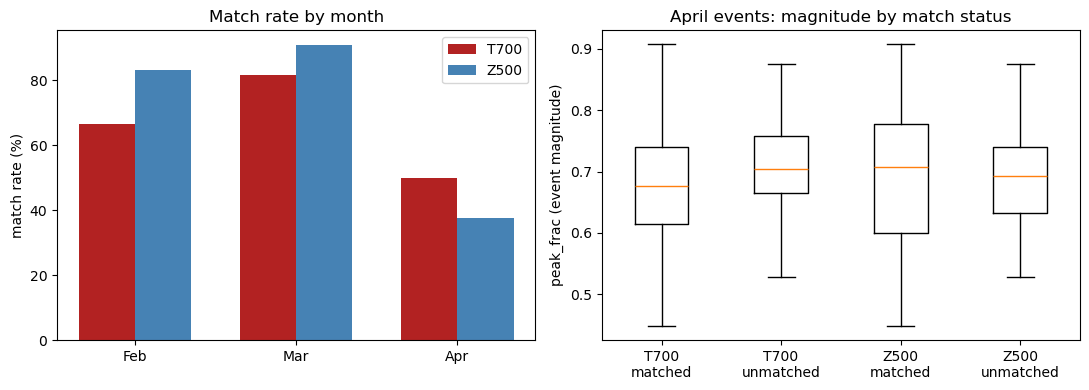

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
months = by_month.index
width = 0.35
ax.bar(months - width/2, by_month.t700_match_pct, width, label='T700', color='firebrick')
ax.bar(months + width/2, by_month.z500_match_pct, width, label='Z500', color='steelblue')
ax.set_xticks(months)
ax.set_xticklabels(['Feb', 'Mar', 'Apr'])
ax.set_ylabel('match rate (%)')
ax.set_title('Match rate by month')
ax.legend()

ax = axes[1]
april = melt_janapr[melt_janapr.is_april]
data = [april.loc[april.matched_t700, 'peak_frac'], april.loc[~april.matched_t700, 'peak_frac'],
        april.loc[april.matched_z500, 'peak_frac'], april.loc[~april.matched_z500, 'peak_frac']]
ax.boxplot(data, tick_labels=['T700\nmatched', 'T700\nunmatched', 'Z500\nmatched', 'Z500\nunmatched'])
ax.set_ylabel('peak_frac (event magnitude)')
ax.set_title('April events: magnitude by match status')

plt.tight_layout()
plt.show()


## 6. Robustness check: does the April effect hold under Method C's heat-wave definition?

`CA_methodA_vs_methodC_match_permutation_test.ipynb` found that Method C (5-day-mean-std
heat-wave definition) genuinely outperforms Method A (>=5-day persistence) on its own
chance-adjusted terms -- Method C's excess-over-chance match rate is larger, not just
its raw match rate. That result is specifically about the **atmospheric** heat-wave
definition, not the snow-side melt-event definition (`CA_snowmelt_methodC_5daymean_std.ipynb`'s
own "Method C" is a different, snow-side comparison, and its own verdict there is
mixed -- not defensible for magnitude ranking, which is why this notebook keeps using
the snow-side Method A events throughout). The fair check this motivates is: does the
April match-rate drop found above still show up if the *better-performing* Method C
heat-wave record is used instead of Method A's, or was it partly an artifact of
Method A's sparser calendar?

Same 41 Jan-Apr melt events (Method A, unchanged) and the same April-vs-Jan-Mar split,
now matched against `ca_z500_t700_events_1990-2025_methodC_5daymean.csv` instead of
the mindur5 Method A heat-wave record.

In [8]:
hw_C = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_methodC_5daymean.csv',
                    parse_dates=['start_date', 'end_date'])
hw_C['start_date'] = hw_C.start_date.dt.date
hw_C['end_date'] = hw_C.end_date.dt.date
t700_C = hw_C[(hw_C.variable == '700 hPa temperature (warm)') & (hw_C.threshold_sd == 1)].reset_index(drop=True)
z500_C = hw_C[(hw_C.variable == '500 hPa height (ridging)') & (hw_C.threshold_sd == 1)].reset_index(drop=True)

for col, hw_events in [('matched_t700_C', t700_C), ('matched_z500_C', z500_C)]:
    _, unmatched = lib.overlapping_pairs(melt_janapr, hw_events, a_prefix='melt', b_prefix='hw')
    melt_janapr[col] = ~melt_janapr.index.isin(unmatched.index)

print(f'Method C event counts: T700={len(t700_C)}, Z500={len(z500_C)} '
      f'(Method A was T700={len(t700_A)}, Z500={len(z500_A)})')
print(f'Overall Method C match rate: T700={melt_janapr.matched_t700_C.mean()*100:.0f}%, '
      f'Z500={melt_janapr.matched_z500_C.mean()*100:.0f}% (Method A was 61%/59%)\n')

by_month_C = melt_janapr.groupby('month').agg(
    n=('matched_t700_C', 'size'),
    t700C_match_pct=('matched_t700_C', lambda s: 100 * s.mean()),
    z500C_match_pct=('matched_z500_C', lambda s: 100 * s.mean()),
)
by_month_C

Method C event counts: T700=137, Z500=139 (Method A was T700=47, Z500=48)
Overall Method C match rate: T700=93%, Z500=93% (Method A was 61%/59%)



,n,t700C_match_pct,z500C_match_pct
month,,,
2,6,100.0,100.0
3,11,100.0,100.0
4,24,87.5,87.5


In [9]:
print('Fisher exact test and bootstrap CI, April vs. Jan-Mar, Method C:\n')
for label, col in [('T700', 'matched_t700_C'), ('Z500', 'matched_z500_C')]:
    april = melt_janapr[melt_janapr.is_april]
    janmar = melt_janapr[~melt_janapr.is_april]
    a_m, a_n = int(april[col].sum()), len(april)
    j_m, j_n = int(janmar[col].sum()), len(janmar)
    table = [[a_m, a_n - a_m], [j_m, j_n - j_m]]
    odds, p = fisher_exact(table)

    a_vals, j_vals = april[col].values.astype(bool), janmar[col].values.astype(bool)
    diffs = np.array([
        rng.choice(a_vals, size=len(a_vals), replace=True).mean()
        - rng.choice(j_vals, size=len(j_vals), replace=True).mean()
        for _ in range(N_BOOT)
    ])
    lo, hi = np.percentile(diffs, [2.5, 97.5])

    print(f'{label}: April {a_m}/{a_n} ({100*a_m/a_n:.0f}%) vs. Jan-Mar {j_m}/{j_n} ({100*j_m/j_n:.0f}%)')
    print(f'  Fisher exact: odds ratio={odds:.2f}, p={p:.4f}')
    print(f'  Bootstrap 95% CI for (April rate - Jan-Mar rate): [{100*lo:.0f}, {100*hi:.0f}] pts\n')

print('Note: Jan-Mar matches 100% (17/17) under Method C for both variables -- zero '
      'variance in that group. A logistic trend test (as used for Method A above) hits '
      'quasi-complete separation here and its MLE coefficient/p-value are not '
      'meaningful (statsmodels fails to converge); Fisher\'s exact test and the '
      'bootstrap CI, both used above, remain valid under this condition and are the '
      'tests to trust for Method C.')


Fisher exact test and bootstrap CI, April vs. Jan-Mar, Method C:

T700: April 21/24 (88%) vs. Jan-Mar 17/17 (100%)
  Fisher exact: odds ratio=0.00, p=0.2537
  Bootstrap 95% CI for (April rate - Jan-Mar rate): [-25, 0] pts



Z500: April 21/24 (88%) vs. Jan-Mar 17/17 (100%)
  Fisher exact: odds ratio=0.00, p=0.2537
  Bootstrap 95% CI for (April rate - Jan-Mar rate): [-25, 0] pts

Note: Jan-Mar matches 100% (17/17) under Method C for both variables -- zero variance in that group. A logistic trend test (as used for Method A above) hits quasi-complete separation here and its MLE coefficient/p-value are not meaningful (statsmodels fails to converge); Fisher's exact test and the bootstrap CI, both used above, remain valid under this condition and are the tests to trust for Method C.


In [10]:
print('Magnitude comparison within April, Method C (same proxies as Section 4):\n')
for col in ['matched_t700_C', 'matched_z500_C']:
    april = melt_janapr[melt_janapr.is_april]
    matched, unmatched = april[april[col]], april[~april[col]]
    if len(matched) == 0 or len(unmatched) == 0:
        print(f'  {col}: skipped (one group is empty)')
        continue
    for mag in ['duration_days', 'peak_frac', 'mean_frac']:
        stat, p = mannwhitneyu(matched[mag], unmatched[mag], alternative='two-sided')
        print(f'  {col} / {mag}: matched median={matched[mag].median():.3f} (n={len(matched)}) '
              f'vs. unmatched median={unmatched[mag].median():.3f} (n={len(unmatched)}) -- MWU p={p:.2f}')


Magnitude comparison within April, Method C (same proxies as Section 4):

  matched_t700_C / duration_days: matched median=8.000 (n=21) vs. unmatched median=6.000 (n=3) -- MWU p=0.96
  matched_t700_C / peak_frac: matched median=0.692 (n=21) vs. unmatched median=0.712 (n=3) -- MWU p=0.50
  matched_t700_C / mean_frac: matched median=0.530 (n=21) vs. unmatched median=0.528 (n=3) -- MWU p=1.00
  matched_z500_C / duration_days: matched median=8.000 (n=21) vs. unmatched median=6.000 (n=3) -- MWU p=0.96
  matched_z500_C / peak_frac: matched median=0.692 (n=21) vs. unmatched median=0.712 (n=3) -- MWU p=0.50
  matched_z500_C / mean_frac: matched median=0.530 (n=21) vs. unmatched median=0.528 (n=3) -- MWU p=1.00


### Section 6 takeaway

**The direction of the April effect survives under Method C, but loses statistical
power because Method C's calendar is dense enough to hit a ceiling.** Jan-Mar matches
100% (17/17, both variables) under Method C -- there's no room left to detect a
seasonal *drop* when the comparison group is already saturated at the top of the
scale. April comes in at 88% (21/24) -- still lower, same direction as Method A's
result, but Fisher's exact test no longer clears significance (p=0.25, vs. Method A
Z500's p=0.0014) because an 88%-vs-100% gap is much harder to distinguish from chance
than Method A's 38%-vs-88% gap, even though the *relative* shortfall in April is
qualitatively the same story.

This is a real, honest limitation of using Method C for this particular question, not
a reason to prefer Method A's result as "more true": Method C's looser definition
mechanically compresses the matching Jan-Mar group toward 100%, which is exactly the
kind of base-rate/ceiling effect the earlier permutation test was built to catch for
the *overall* match rate -- it just resurfaces here as reduced power for a *seasonal
subgroup* comparison instead. The magnitude finding replicates cleanly either way:
unmatched April events are statistically indistinguishable in size from matched ones
under Method C too (all MWU p >= 0.5), the same null as Method A's Section 4 -- so the
"unmatched April events aren't just smaller, routine melt-outs" conclusion is not an
artifact of which heat-wave definition is used.

## 7. Conclusion

**The naive "improves later in the season" read of the raw percentages does not
survive formal testing -- if anything, the opposite is true for Z500, and April is
not a smaller/more-routine population of events.**

| | April | Jan-Mar | Fisher p | bootstrap 95% CI (April - Jan-Mar) | logit month trend p |
|---|---|---|---|---|---|
| T700 | 12/24 (50%) | 13/17 (76%) | 0.11 | [-53, +4] pts | 0.20 (negative, not significant) |
| Z500 | 9/24 (38%) | 15/17 (88%) | **0.0014** | **[-75, -25] pts** | **0.012 (significant negative trend)** |

- **Z500's seasonal drop is real, not noise.** Both the direct April-vs-Jan-Mar test
  and the independent linear-trend test agree: match rate declines with month, and
  the effect is large (odds ratio 0.08, i.e. an April event is roughly 12x less
  likely to overlap a Z500 ridging event than a Feb/Mar event, holding nothing else
  fixed).
- **T700 shows the same direction but doesn't clear significance** (Fisher p=0.11,
  CI for the gap includes a thin sliver above zero). With only 17 Jan-Mar events to
  compare against, this test is underpowered to resolve an effect the same size as
  Z500's -- "not significant" here is a weak null, not evidence the two variables
  genuinely disagree.
- **Unmatched April events are not smaller or more routine.** Every one of the six
  magnitude comparisons (2 variables x 3 proxies) in April comes back statistically
  indistinguishable (all MWU p > 0.4), and the same null holds for the Jan-Mar
  contrast. This rules out the simplest version of "April misses are just ordinary,
  small climatological melt-out that doesn't need a ridge" -- the events Z500/T700
  fail to catch in April are the same size, duration, and spatial extent as the ones
  they do catch.

- **The direction holds under Method C, the better-performing heat-wave
  definition, but the test loses power there.** Section 6 reruns the same split
  against Method C's heat-wave record (shown to genuinely beat Method A on its own
  chance-adjusted terms in the companion permutation-test notebook): April is still
  lower than Jan-Mar (88% vs. 100%), but Jan-Mar's 100% match rate leaves no room to
  detect a drop with statistical confidence (Fisher p=0.25) -- a ceiling effect, not
  evidence the April effect is specific to Method A's sparser calendar. The magnitude
  null (unmatched April events aren't smaller) replicates cleanly under Method C too.

**What this means for the project's framing.** The original storyline -- "apart from
a few exceptions, the atmospheric fields indicate melt events well, and perhaps
better later in the season" -- needs revision on the seasonal point specifically:
April, the single most common onset month (59% of the whole Jan-Apr sample), is where
the Z500/T700 signal is *weakest*, not strongest, and that weakening is statistically
real for Z500. Because the missed April events are equally large, this looks less
like "a different, lesser melt mechanism takes over in April" and more like either
(a) a genuinely different *driver* of comparably large declines that doesn't clear
this detector's >=5-day persistence bar (e.g. shorter, sharper warm pulses, or
mechanisms other than ridging-driven warming), or (b) the detector itself getting
less sensitive by April -- plausible given that climatological variance structure
already proved sensitive to window/duration choices elsewhere in this project (the
WINDOW and MIN_DURATION sensitivity sweeps). This notebook can't distinguish those
two explanations; doing so would need either a <5-day persistence sensitivity check
restricted to April, or a direct look at April's climatological Z500/T700 variance
relative to Feb/Mar.

**A third, literature-backed explanation (added after review): reduced snowpack cold content, not a detector or mechanism failure.** Guo and He (2026, *Environ. Res. Lett.* 21, 194013, "Heatwaves drive rapid snowmelt and disrupt streamflow in the western United States") analyze heatwave-driven snowmelt across 823 SNOTEL stations WUS-wide (2001-2024, a local station-temperature-percentile heatwave definition, not a synoptic Z500/T700 index) and find the heatwave-melt coupling is *strongest* in spring, with the longest post-heatwave persistence (tied with winter; shortest in fall/summer) -- attributed to spring snowpack's reduced cold content and higher liquid water content (near-isothermal, close to 0C), meaning *less* additional heating is needed to trigger rapid melt (citing Jennings et al. 2018). Applied here: by April, Sierra snowpack may already be primed enough that an ordinary warm spell -- one that never clears the >=1-sigma/>=5-day synoptic ridging threshold this project's heat-wave definition requires -- is sufficient to produce a rapid-decline event. That would explain the lower April match rate without requiring either a different melt mechanism or a weaker detector: the physical trigger threshold for rapid melt itself drops as the season progresses, lowering the fraction of April events that need a detected synoptic heat wave to occur at all. This is consistent with, and arguably the most parsimonious reading of, the magnitude-indistinguishability finding above (Section 4) -- unmatched April events are the same size as matched ones because size is set by how primed the snowpack already is, not by whether a synoptic ridge happened to be present.